<a href="https://colab.research.google.com/github/ryanlin3124/Pytorch-exercises/blob/main/extras/exercises/03_pytorch_computer_vision_exercises.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 03. PyTorch Computer Vision Exercises

The following is a collection of exercises based on computer vision fundamentals in PyTorch.

They're a bunch of fun.

You're going to get to write plenty of code!

## Resources

1. These exercises are based on [notebook 03 of the Learn PyTorch for Deep Learning course](https://www.learnpytorch.io/03_pytorch_computer_vision/).
2. See a live [walkthrough of the solutions (errors and all) on YouTube](https://youtu.be/_PibmqpEyhA).
  * **Note:** Going through these exercises took me just over 3 hours of solid coding, so you should expect around the same.
3. See [other solutions on the course GitHub](https://github.com/mrdbourke/pytorch-deep-learning/tree/main/extras/solutions).

In [1]:
# Check for GPU
!nvidia-smi

Wed Oct 21 17:17:08 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   36C    P8             11W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
# Import torch
import torch

# Exercises require PyTorch > 1.10.0
print(torch.__version__)

# TODO: Setup device agnostic code
device = "cuda" if torch.cuda.is_available() else "cpu"
device

2.11.0+cu130


'cuda'

## 1. What are 3 areas in industry where computer vision is currently being used?

1. Car Vision, where computer vision is being used to create self-driving cars
2. Video game industry, using face recognition for horror games
3. Medical imaging, for segmentation and tumor detection

## 2. Search "what is overfitting in machine learning" and write down a sentence about what you find.

Based on my prior knowledge, overfitting is when the data is fitted too tightly with the training data. This makes it so that when the model is being tested with, it might not predict the correct value.


## 3. Search "ways to prevent overfitting in machine learning", write down 3 of the things you find and a sentence about each.
> **Note:** there are lots of these, so don't worry too much about all of them, just pick 3 and start with those.

1. Using a less complex model, although more complex models have their own time and place, for less complex data, complex models have a tendency to overfit.
2. Using more generalized data, if you were only to use data from 1 source, if the model were to be tested from data obtained from another source, the model might not fit with the second source

3. Remove any duplicate data points, as this can lead to overfitting

## 4. Spend 20-minutes reading and clicking through the [CNN Explainer website](https://poloclub.github.io/cnn-explainer/).

* Upload your own example image using the "upload" button on the website and see what happens in each layer of a CNN as your image passes through it.

## 5. Load the [`torchvision.datasets.MNIST()`](https://pytorch.org/vision/stable/generated/torchvision.datasets.MNIST.html#torchvision.datasets.MNIST) train and test datasets.

In [3]:
from torch import nn
import torchvision
from torchvision import datasets
from torchvision.transforms import ToTensor

import matplotlib.pyplot as plt

# training data
train_data = datasets.MNIST(
    root="data",
    train=True,
    download=True,
    transform=ToTensor(),
    target_transform=None
)

# Testing data
test_data = datasets.MNIST(
    root="data",
    train=False,
    download=True,
    transform=ToTensor(),
    target_transform=None
)

100%|██████████| 9.91M/9.91M [00:00<00:00, 18.3MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 481kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.58MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 10.5MB/s]


## 6. Visualize at least 5 different samples of the MNIST training dataset.

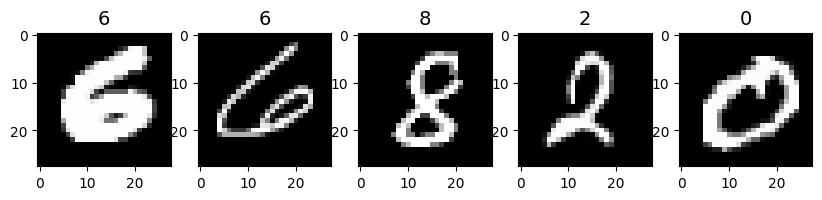

['0 - zero',
 '1 - one',
 '2 - two',
 '3 - three',
 '4 - four',
 '5 - five',
 '6 - six',
 '7 - seven',
 '8 - eight',
 '9 - nine']

In [4]:
SEED = 42
torch.manual_seed(SEED)
fig = plt.figure(figsize=(10, 10))
rows, cols = 1, 5
for i in range(1, rows * cols + 1):
    sample_idx = torch.randint(0, len(train_data), size=(1,)).item()
    img, label = train_data[sample_idx]
    fig.add_subplot(rows, cols, i)
    plt.imshow(img.squeeze(), cmap="gray")
    plt.title(label, fontsize=14)
plt.show()

class_name = train_data.classes
class_name

## 7. Turn the MNIST train and test datasets into dataloaders using `torch.utils.data.DataLoader`, set the `batch_size=32`.

In [5]:
from torch.utils.data import DataLoader

BATCHSIZE = 32

train_dataloader = DataLoader(train_data, batch_size= BATCHSIZE, shuffle=True)
test_dataloader = DataLoader(test_data, batch_size= BATCHSIZE, shuffle=False)

print(f"Dataloaders: {train_dataloader, test_dataloader}")
print(f"Length of train dataloader: {len(train_dataloader)} batches of {BATCHSIZE}")
print(f"Length of test dataloader: {len(test_dataloader)} batches of {BATCHSIZE}")

Dataloaders: (<torch.utils.data.dataloader.DataLoader object at 0x7f81daf49e80>, <torch.utils.data.dataloader.DataLoader object at 0x7f81da687110>)
Length of train dataloader: 1875 batches of 32
Length of test dataloader: 313 batches of 32


## 8. Recreate `model_2` used in notebook 03 (the same model from the [CNN Explainer website](https://poloclub.github.io/cnn-explainer/), also known as TinyVGG) capable of fitting on the MNIST dataset.

In [6]:
class MNISTmodel_0(nn.Module):
    def __init__(self, input_shape: int, hidden_units: int, output_shape: int):
      super().__init__()
      self.block1 = nn.Sequential(
        nn.Conv2d(in_channels=input_shape, out_channels=hidden_units, kernel_size=3, padding=1, stride=1),
        nn.ReLU(),
        nn.Conv2d(in_channels=hidden_units, out_channels=hidden_units, kernel_size=3, padding=1, stride=1),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size=2, stride=2)
      )
      self.block2 = nn.Sequential(
          nn.Conv2d(in_channels=hidden_units, out_channels=hidden_units, kernel_size=3, padding=1, stride=1),
          nn.ReLU(),
          nn.Conv2d(in_channels=hidden_units, out_channels=hidden_units, kernel_size=3, padding=1, stride=1),
          nn.ReLU(),
          nn.MaxPool2d(kernel_size=2, stride=2)
      )
      self.classifier = nn.Sequential(
          nn.Flatten(),
          nn.Linear(in_features=hidden_units*7*7, out_features=output_shape)
      )
    def forward(self, x: torch.Tensor):
      x = self.block1(x)
      x = self.block2(x)
      x = self.classifier(x)
      return x
model_0 = MNISTmodel_0(input_shape=1, hidden_units=10, output_shape=len(class_name)).to(device)
model_0


MNISTmodel_0(
  (block1): Sequential(
    (0): Conv2d(1, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (block2): Sequential(
    (0): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=490, out_features=10, bias=True)
  )
)

## 9. Train the model you built in exercise 8. for 5 epochs on CPU and GPU and see how long it takes on each.

In [7]:
torch.manual_seed(SEED)

loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model_0.parameters(), lr=0.1)

from timeit import default_timer as timer


In [8]:
!pip -q install torchmetrics
from torchmetrics import Accuracy
acc_fn = Accuracy(task="multiclass", num_classes=len(class_name)).to(device)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 27.9 MB/s eta 0:00:00


In [9]:
def train_step(model: torch.nn.Module,
               data_loader: torch.utils.data.DataLoader,
               loss_fn: torch.nn.Module,
               optimizer: torch.optim.Optimizer,
               acc_fn,
               device: torch.device = device):
  train_loss, train_acc = 0, 0
  model.to(device)
  model.train()
  for batch, (X,y) in enumerate(data_loader):
    X, y = X.to(device), y.to(device)

    # Forward Pass
    y_pred = model(X)
    # Loss
    loss = loss_fn(y_pred, y)
    train_loss += loss
    train_acc += acc_fn(y_pred.argmax(dim=1), y)
    # Zero Grad
    optimizer.zero_grad()
    # Loss Backward
    loss.backward()
    # Grad Step
    optimizer.step()
  train_loss /= len(data_loader)
  train_acc /= len(data_loader)
  print(f"Train loss: {train_loss:.5f} | Train accuracy: {train_acc:.2f}%")

def test_step(model: torch.nn.Module,
              data_loader: torch.utils.data.DataLoader,
              loss_fn: torch.nn.Module,
              acc_fn,
              device: torch.device = device):
  test_loss, test_acc = 0, 0
  model.to(device)
  model.eval()
  with torch.inference_mode():
    for batch, (X, y) in enumerate(data_loader):
      X, y = X.to(device), y.to(device)

      #Forward Pass
      y_test = model(X)

      # Calc Loss and Acc
      test_loss += loss_fn(y_test, y)
      test_acc += acc_fn(y_test.argmax(dim=1), y)
    test_loss /= len(data_loader)
    test_acc /= len(data_loader)
    print(f"Test loss: {test_loss:.5f} | Test accuracy: {test_acc:.2f}%\n")

In [10]:
epochs = 5
model_0_start_timer = timer()
for epoch in range(epochs):
  train_step(model_0, train_dataloader, loss_fn, optimizer, acc_fn)
  test_step(model_0, test_dataloader, loss_fn, acc_fn)

model_0_end_timer = timer()
print(f"Total training time: {model_0_end_timer - model_0_start_timer:.3f} seconds")


Train loss: 0.38249 | Train accuracy: 0.87%
Test loss: 0.06902 | Test accuracy: 0.98%

Train loss: 0.07029 | Train accuracy: 0.98%
Test loss: 0.05580 | Test accuracy: 0.98%

Train loss: 0.05312 | Train accuracy: 0.98%
Test loss: 0.05236 | Test accuracy: 0.98%

Train loss: 0.04506 | Train accuracy: 0.99%
Test loss: 0.04377 | Test accuracy: 0.99%

Train loss: 0.03854 | Train accuracy: 0.99%
Test loss: 0.03766 | Test accuracy: 0.99%

Total training time: 80.488 seconds


## 10. Make predictions using your trained model and visualize at least 5 of them comparing the prediciton to the target label.

In [11]:
def make_predictions(model: torch.nn.Module, data: list, device: torch.device = device):
  pred_probs = []
  model.eval()
  with torch.inference_mode():
    for sample in data:
      sample = torch.unsqueeze(sample, dim=0).to(device)
      pred_logit = model(sample)
      pred_prob = torch.softmax(pred_logit.squeeze(), dim=0)
      pred_probs.append(pred_prob.cpu())

  return torch.stack(pred_probs)

In [12]:
from IPython.testing import test
import random
random.seed(SEED)
test_samples = []
test_labels = []
for sample, label in random.sample(list(test_data), k = 9):
  test_samples.append(sample)
  test_labels.append(label)

test_samples[0].shape, test_labels[0], class_name[test_labels[0]]

(torch.Size([1, 28, 28]), 2, '2 - two')

In [13]:
pred_probs = make_predictions(model_0, test_samples)
pred_probs[:2]

tensor([[2.6426e-08, 1.1345e-08, 1.0000e+00, 1.6677e-08, 5.3427e-18, 5.8250e-16,
         1.7570e-13, 1.0264e-08, 1.6578e-06, 2.6604e-10],
        [1.3740e-05, 9.9285e-01, 4.0385e-04, 2.0639e-05, 6.8781e-06, 3.5420e-04,
         4.0020e-04, 1.7926e-04, 1.8792e-03, 3.8881e-03]])

In [14]:
pred_classes = pred_probs.argmax(dim=1)
pred_classes, test_labels

(tensor([2, 1, 2, 4, 6, 6, 4, 9, 1]), [2, 1, 2, 4, 6, 6, 4, 9, 1])

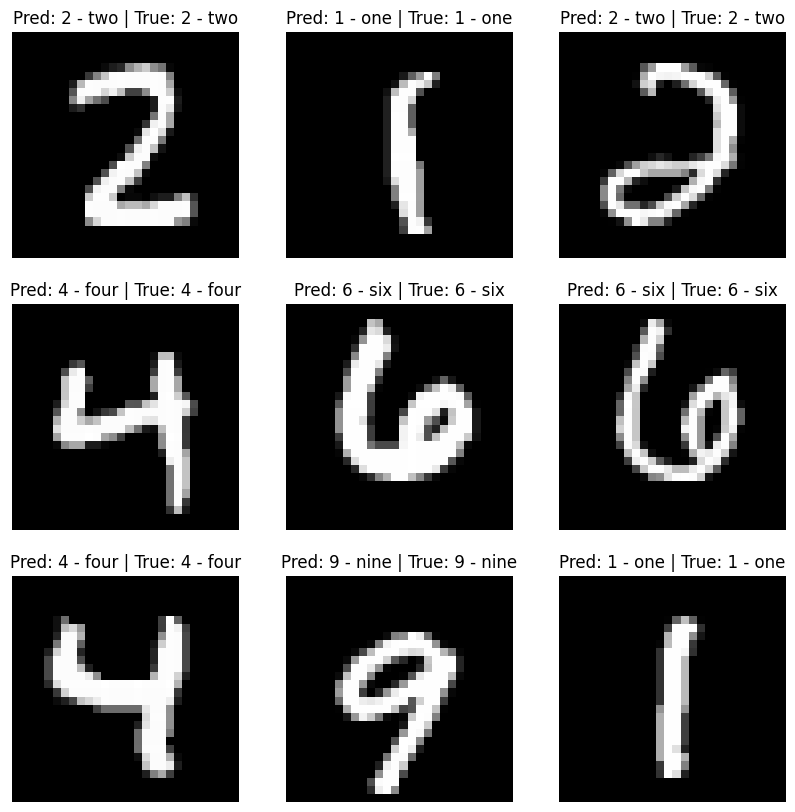

In [15]:
plt.figure(figsize=(10, 10))
rows, cols = 3, 3
for i, sample in enumerate(test_samples):
  plt.subplot(rows, cols, i+1)
  plt.imshow(sample.squeeze(), cmap="gray")
  pred_label = class_name[pred_classes[i]]
  true_label = class_name[test_labels[i]]
  plt.title(f"Pred: {pred_label} | True: {true_label}")
  plt.axis(False)
plt.show()

## 11. Plot a confusion matrix comparing your model's predictions to the truth labels.

In [16]:
from tqdm.auto import tqdm

y_preds = []
model_0.eval()
with torch.inference_mode():
  for X, y in tqdm(test_dataloader):
    X, y = X.to(device), y.to(device)
    y_logits = model_0(X)
    y_pred = torch.softmax(y_logits, dim=1).argmax(dim=1)
    y_preds.append(y_pred.cpu())

y_preds_tensor = torch.cat(y_preds)
y_preds[:10]

  0%|          | 0/313 [00:00<?, ?it/s]

[tensor([7, 2, 1, 0, 4, 1, 4, 9, 5, 9, 0, 6, 9, 0, 1, 5, 9, 7, 5, 4, 9, 6, 6, 5,
         4, 0, 7, 4, 0, 1, 3, 1]),
 tensor([3, 4, 7, 2, 7, 1, 2, 1, 1, 7, 4, 2, 3, 5, 1, 2, 4, 4, 6, 3, 5, 5, 6, 0,
         4, 1, 9, 5, 7, 8, 9, 3]),
 tensor([7, 4, 6, 4, 3, 0, 7, 0, 2, 9, 1, 7, 3, 2, 9, 7, 7, 6, 2, 7, 8, 4, 7, 3,
         6, 1, 3, 6, 9, 3, 1, 4]),
 tensor([1, 7, 6, 9, 6, 0, 5, 4, 9, 9, 2, 1, 9, 4, 8, 7, 3, 9, 7, 4, 4, 4, 9, 2,
         5, 4, 7, 6, 7, 9, 0, 5]),
 tensor([8, 5, 6, 6, 5, 7, 8, 1, 0, 1, 6, 4, 6, 7, 3, 1, 7, 1, 8, 2, 0, 2, 9, 9,
         5, 5, 1, 5, 6, 0, 3, 4]),
 tensor([4, 6, 5, 4, 6, 5, 4, 5, 1, 4, 4, 7, 2, 3, 2, 7, 1, 8, 1, 8, 1, 8, 5, 0,
         8, 9, 2, 5, 0, 1, 1, 1]),
 tensor([0, 9, 0, 3, 1, 6, 4, 2, 3, 6, 1, 1, 1, 3, 9, 5, 2, 9, 4, 5, 9, 3, 9, 0,
         3, 6, 5, 5, 7, 2, 2, 7]),
 tensor([1, 2, 8, 4, 1, 7, 3, 3, 8, 8, 7, 9, 2, 2, 4, 1, 5, 9, 8, 7, 2, 3, 0, 2,
         4, 2, 4, 1, 9, 5, 7, 7]),
 tensor([2, 8, 2, 6, 8, 5, 7, 7, 9, 1, 8, 1, 8, 0, 3, 0, 1, 9, 9, 4, 1, 

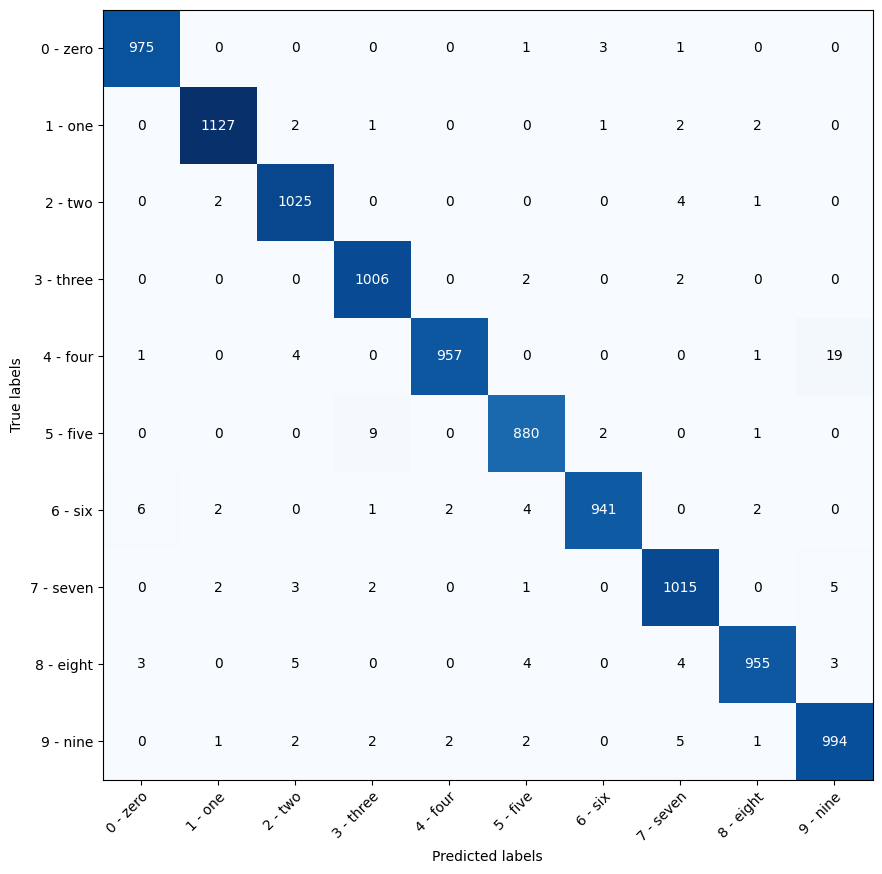

In [18]:
from torchmetrics import ConfusionMatrix
from mlxtend.plotting import plot_confusion_matrix

cm = ConfusionMatrix(task="multiclass", num_classes=len(class_name))
cm_tensor = cm(preds = y_preds_tensor, target = test_data.targets)

fig, ax = plot_confusion_matrix(conf_mat=cm_tensor.numpy(),
                                class_names=class_name,
                                figsize=(10, 10),
                                cmap=plt.cm.Blues)
plt.xlabel("Predicted labels")
plt.ylabel("True labels")
plt.show()

## 12. Create a random tensor of shape `[1, 3, 64, 64]` and pass it through a `nn.Conv2d()` layer with various hyperparameter settings (these can be any settings you choose), what do you notice if the `kernel_size` parameter goes up and down?

## 13. Use a model similar to the trained `model_2` from notebook 03 to make predictions on the test [`torchvision.datasets.FashionMNIST`](https://pytorch.org/vision/main/generated/torchvision.datasets.FashionMNIST.html) dataset.
* Then plot some predictions where the model was wrong alongside what the label of the image should've been.
* After visualing these predictions do you think it's more of a modelling error or a data error?
* As in, could the model do better or are the labels of the data too close to each other (e.g. a "Shirt" label is too close to "T-shirt/top")?